In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

from taia1dvfd.analysis import get_model_variable

In [ ]:
OUT = "/home/mnex/Desktop/1DV_FD/experiments/4_Eco3M_test/output/"
FILE = OUT + "eco3M_minimal.nc"

# From quotas_sim.txt / config.ini
Q_MIN_PHY_C, Q_MAX_PHY_C = 1.26e-13, 3.78e-13     # mol C / cell
CHL_C_MAX = 1.20                                   # g Chl / mol C
CHL_C_REF = 12.0 / 70.0                            # initial value

NDAYS = 720

In [10]:
def load(name):
    z, t, mean, var = get_model_variable(FILE, name)
    return z, t / 86400.0, mean, var

def daily_mean(t, x, n_days):
    day = np.floor(t).astype(int)
    out = np.full(n_days, np.nan)
    for d in range(n_days):
        sel = (day == d) & np.isfinite(x)
        if sel.any():
            out[d] = x[sel].mean()
    return np.arange(n_days) + 0.5, out

def _hov(ax, t, z, field, label, log=False, cmap="viridis"):
    pos = field[field > 0]
    if log and pos.size:
        norm = LogNorm(vmin=max(pos.min(), pos.max() * 1e-5), vmax=pos.max())
        field = np.where(field > 0, field, np.nan)
    else:
        norm = None
    pc = ax.pcolormesh(t, z, field.T, shading="nearest", norm=norm, cmap=cmap)        
    ax.set_ylabel("Depth (m)")
    plt.colorbar(pc, ax=ax, label=label, pad=0.01)
    return pc

Text(0.5, 1.0, 'Temperature')

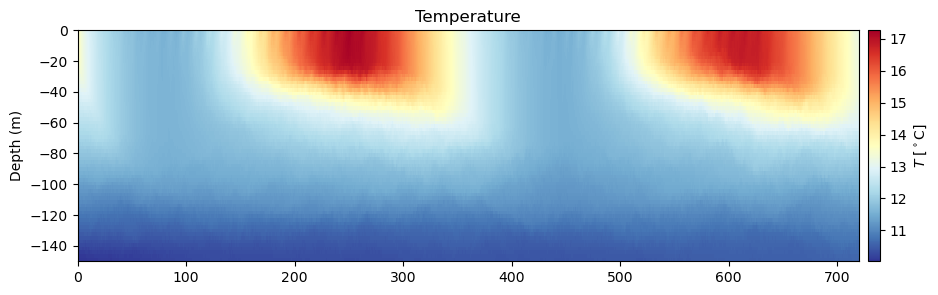

In [11]:
z, t, temp, _ = load("temp")

fig, ax = plt.subplots(1, 1, figsize=(12, 3), sharex=True)
_hov(ax, t, z, temp, r"$T$ [$^\circ$C]", cmap="RdYlBu_r")
ax.set_title("Temperature")

Text(0.5, 0, 'Time (days)')

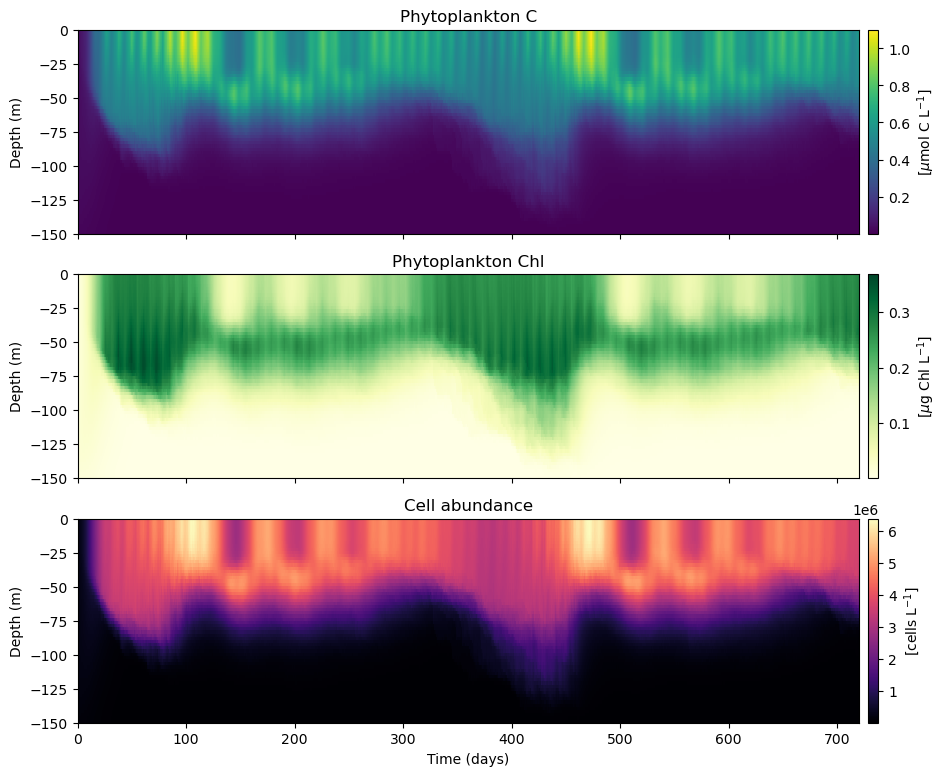

In [12]:
z, t, c, _ = load("bgc_phy_PHY_C")
_, _, chl, _ = load("bgc_phy_PHY_Chl")
_, _, cell, _ = load("bgc_phy_PHY_cell")

fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
_hov(axs[0], t, z, c * 1e6, r"[$\mu$mol C L$^{-1}$]")
axs[0].set_title("Phytoplankton C")

_hov(axs[1], t, z, chl * 1e6, r"[$\mu$g Chl L$^{-1}$]", cmap="YlGn")
axs[1].set_title("Phytoplankton Chl")

_hov(axs[2], t, z, cell, r"[cells L$^{-1}$]", cmap="magma")
axs[2].set_title("Cell abundance")
axs[2].set_xlabel("Time (days)")

# Phytoplankton Chlorophyll

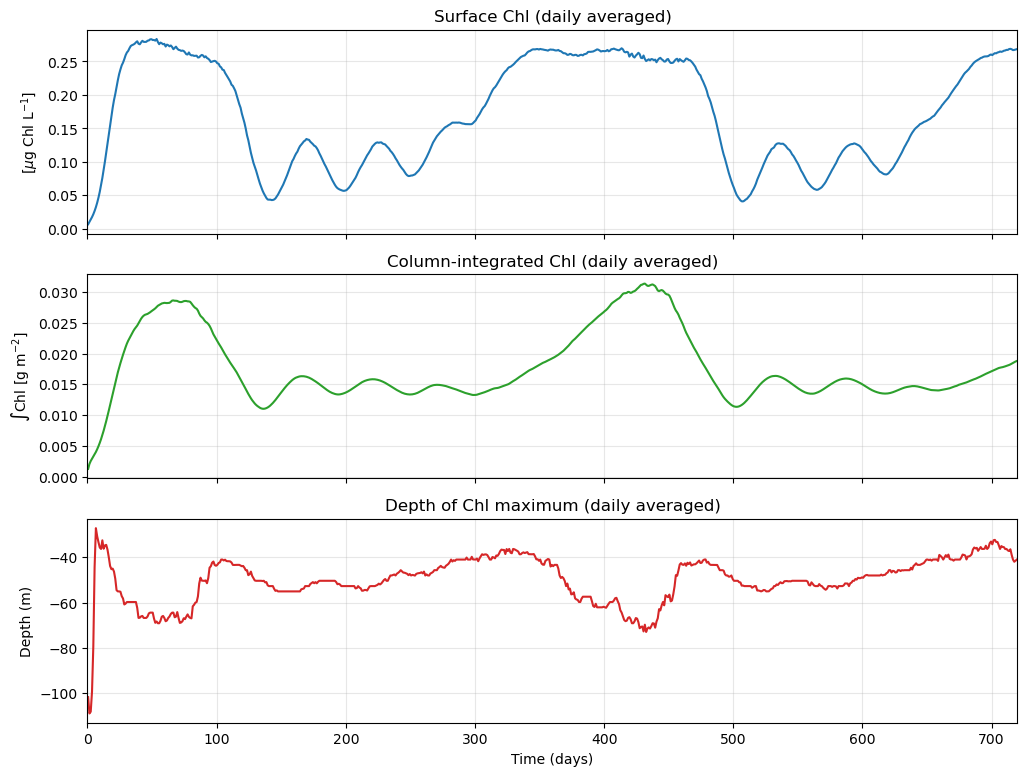

In [13]:
z, t, chl, _ = load("bgc_phy_PHY_Chl")
td, chl_srf = daily_mean(t, chl[:, 0], NDAYS)

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax[0].plot(td, chl_srf*1e6, color = 'C0')
ax[0].set_title("Surface Chl (daily averaged)")
ax[0].set_ylabel(r"[$\mu$g Chl L$^{-1}$]")
ax[0].grid(alpha = 0.3)
ax[0].set_xlim(0, 720)

dz = abs(z[1] - z[0])
int_chl = chl.sum(axis=1) * dz * 1e3    # g Chl m-2
td, int_chl = daily_mean(t, int_chl, NDAYS)

ax[1].set_title("Column-integrated Chl (daily averaged)")
ax[1].plot(td, int_chl, color="C2")
ax[1].set_ylabel(r"$\int$Chl [g m$^{-2}$]")
ax[1].grid(alpha=0.3)

# Depth of the chlorophyll maximum
z_dcm = z[np.argmax(chl, axis=1)]
td, z_dcm = daily_mean(t, z_dcm, NDAYS)

ax[2].set_title("Depth of Chl maximum (daily averaged)")
ax[2].plot(td, z_dcm, color = 'C3')
ax[2].set_ylabel("Depth (m)")
ax[2].set_xlabel("Time (days)")
ax[2].grid(alpha=0.3)

normalised carbon quota: [-0.0007, 0.2574]<-- OUT OF BOUNDS


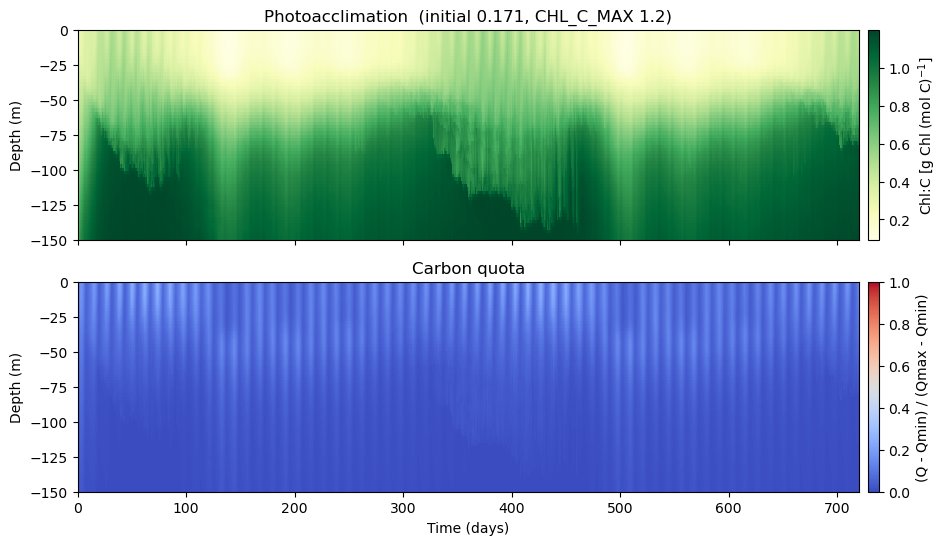

In [14]:
z, t, c, _ = load("bgc_phy_PHY_C")
_, _, chl, _ = load("bgc_phy_PHY_Chl")
_, _, cell, _ = load("bgc_phy_PHY_cell")

with np.errstate(divide="ignore", invalid="ignore"):
    chl_c = np.where(c > 0, chl / c, np.nan)
    q_c = np.where(cell > 0, c / cell, np.nan)

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

pc = axs[0].pcolormesh(t, z, chl_c.T, shading="nearest", cmap="YlGn")
plt.colorbar(pc, ax=axs[0], label=r"Chl:C [g Chl (mol C)$^{-1}$]", pad=0.01)
axs[0].set_title(f"Photoacclimation  (initial {CHL_C_REF:.3f}, CHL_C_MAX {CHL_C_MAX})")
axs[0].set_ylabel("Depth (m)")

# Quota, normalised so 0 = Qmin and 1 = Qmax. Outside [0,1] is a bug.
qn = (q_c - Q_MIN_PHY_C) / (Q_MAX_PHY_C - Q_MIN_PHY_C)
pc = axs[1].pcolormesh(t, z, qn.T, shading="nearest", cmap="coolwarm", vmin=0, vmax=1)
plt.colorbar(pc, ax=axs[1], label="(Q - Qmin) / (Qmax - Qmin)", pad=0.01)
axs[1].set_title("Carbon quota")
axs[1].set_ylabel("Depth (m)")
axs[1].set_xlabel("Time (days)")

lo, hi = np.nanmin(qn), np.nanmax(qn)
print(f"normalised carbon quota: [{lo:.4f}, {hi:.4f}]{'<-- OUT OF BOUNDS' if lo < -1e-6 or hi > 1 + 1e-6 else '   ok'}")